# The split a death rate cannot show

A published firearm death rate mixes two quantities this file does not record. One is how often people are shot. The other is whether a longer trip to a Level I or II center makes that shooting more often fatal.

The naloxone comparison is those two pieces at once. Rescue can lower the chance of death. People can also take more risk where rescue is close. The pieces push the death rate in opposite directions. One cross-section of deaths identifies their sum. It does not identify either piece.

This file has no count of people who were shot and lived, and no years around a center opening. An equation that needs either of those stops here. What follows is a Monte Carlo on `county_distance.csv`: draw the two unknown pieces, keep the draws that still match the counties, and see what is left.

Run this notebook from `trauma-deserts/` so `../data` resolves.


In [1]:
from pathlib import Path

import masking_simulation

masking_simulation.main()
results = __import__("json").loads(Path("masking_results.json").read_text())
slope = results["distance_per_10_miles"]
low, high = results["distance_ci"]
kept = results["assumptions"]["kept_draws"]
draws = results["assumptions"]["draws"]
print(
    f"Density-adjusted distance slope: {slope:+.2f} deaths per 100,000 per 10 miles "
    f"(95% CI {low:+.2f} to {high:+.2f})."
)
print(f"Draws kept: {kept:,} of {draws:,}.")
for scenario in results["scenarios"]:
    print(
        f"{scenario['name']}: slope {scenario['partial_slope_per_10_miles']:+.2f} "
        f"per 10 miles (fatality change {scenario['phi']:+.2f}, "
        f"log shootings {scenario['behavior']:+.2f})."
    )


Density-adjusted slope -0.06 deaths per 100,000 per 10 miles (95% CI -0.19 to +0.06). Kept 444 of 4,000 draws.
Density-adjusted distance slope: -0.06 deaths per 100,000 per 10 miles (95% CI -0.19 to +0.06).
Draws kept: 444 of 4,000.
neither effect: slope +0.00 per 10 miles (fatality change +0.00, log shootings +0.00).
survival only, behavior unchanged: slope +0.98 per 10 miles (fatality change +0.04, log shootings +0.00).
survival offset by more shootings nearby: slope -0.08 per 10 miles (fatality change +0.04, log shootings -0.10).


## What the regression identifies

Holding log density fixed and weighting counties by population, distance does not line up with the firearm death rate. The interval includes zero. With rural share and the race and Hispanic shares in the model as well, removing distance changes the weighted R² by less than 0.001.

The associations that do line up are composition and density. They describe counties. They are not estimates of what would change if a share, the density, or the miles were moved, and they are not a prescription.


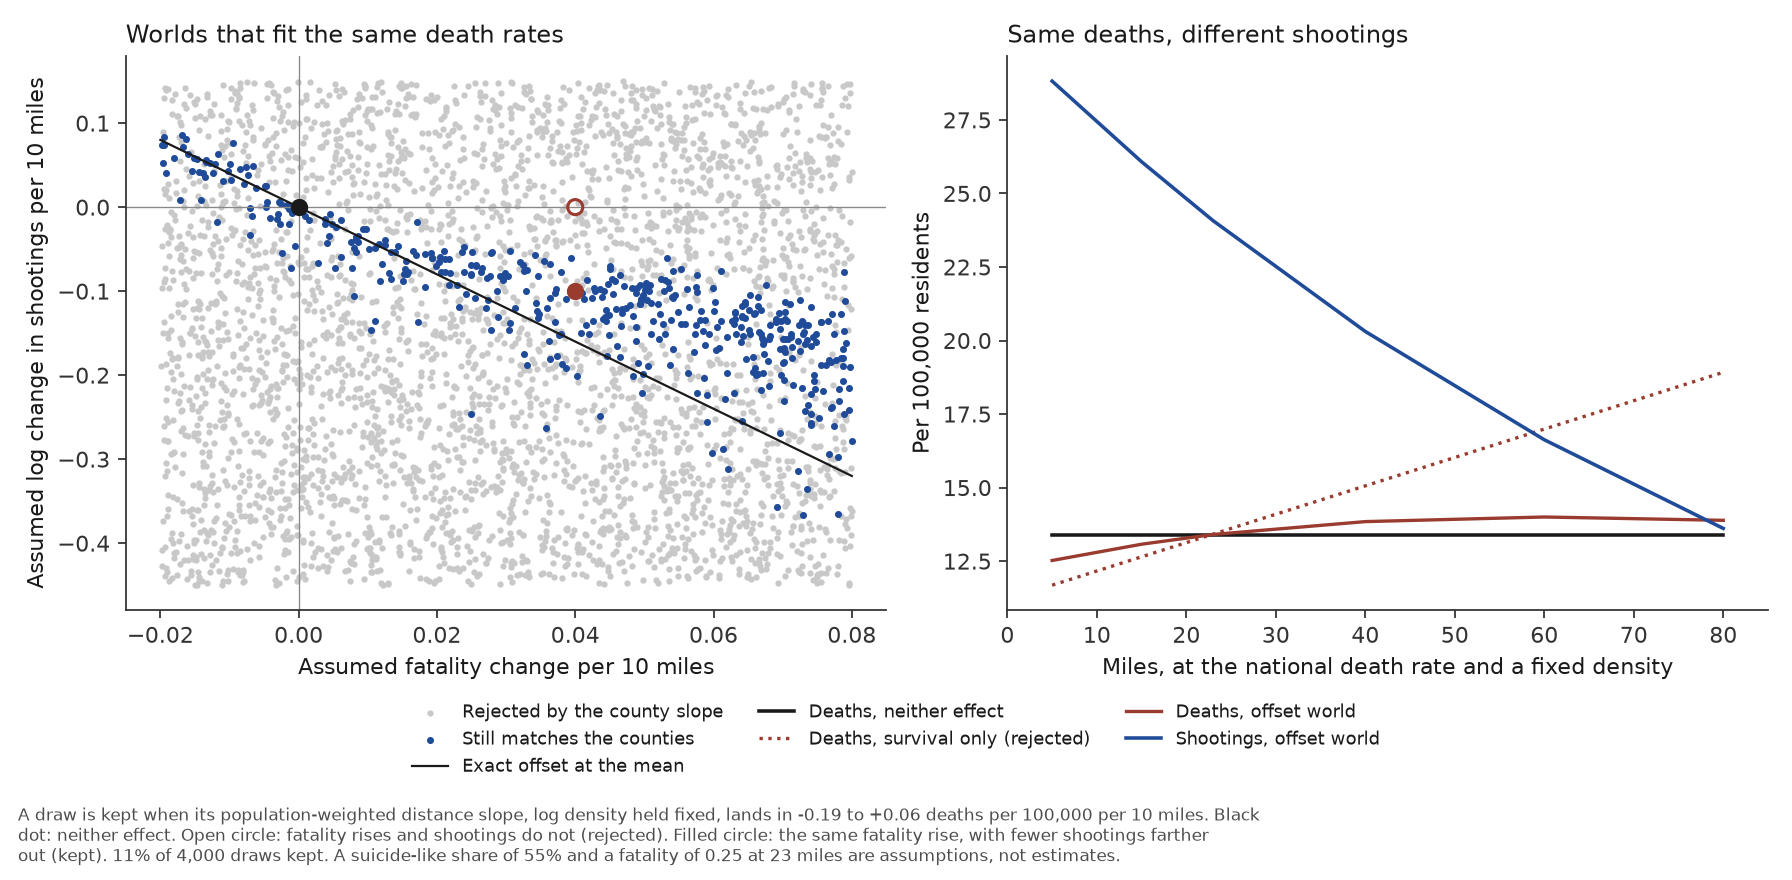

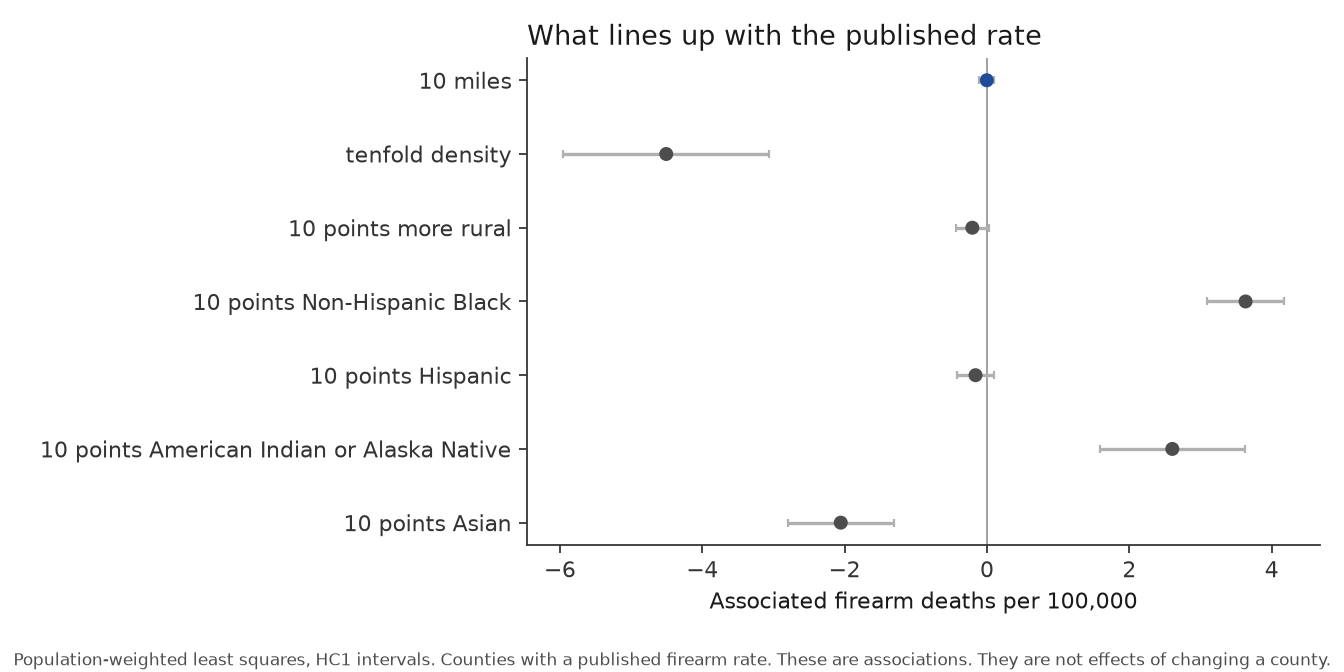

Weighted R² of the full model: 0.52
  remove log density and rural share: R² falls by 0.061
  remove race and Hispanic shares: R² falls by 0.428
  remove distance: R² falls by 0.000

10 miles: -0.00 (95% CI -0.11 to +0.10)
tenfold density: -4.51 (95% CI -5.95 to -3.06)
10 points more rural: -0.21 (95% CI -0.44 to +0.02)
10 points Non-Hispanic Black: +3.63 (95% CI +3.09 to +4.17)
10 points Hispanic: -0.16 (95% CI -0.43 to +0.11)
10 points American Indian or Alaska Native: +2.60 (95% CI +1.58 to +3.63)
10 points Asian: -2.05 (95% CI -2.80 to -1.31)


In [2]:
from IPython.display import Image, display

display(Image("equivalent_worlds.png"))
display(Image("what_lines_up.png"))

print("Weighted R² of the full model:", round(results["full_weighted_r2"], 2))
for row in results["r2_drop"]:
    print(f"  remove {row['group']}: R² falls by {row['r2_drop']:.3f}")
print()
for row in results["contrasts"]:
    print(
        f"{row['contrast']}: {row['associated_deaths_per_100k']:+.2f} "
        f"(95% CI {row['ci_low']:+.2f} to {row['ci_high']:+.2f})"
    )


## Two assumptions, then the draws

The simulation treats 55% of the death rate as suicide-like, because the county file does not split intents, and it treats the fatality of the remaining shootings as 0.25 at 23 miles. Neither number is estimated here.

Four thousand draws vary the fatality change per 10 miles and the log change in shootings per 10 miles. A draw is kept when the death rate it produces, refit on the real counties, has a density-adjusted distance slope inside the interval from the published rates.

The kept draws fall on a line. One end is no distance effect. Farther along it, fatality rises with miles and shootings fall with miles by enough to cancel. The open circle in the figure, fatality rising and shootings unchanged, is off that line and is rejected. The filled circle is one kept cancel. The counties do not choose the point.


In [3]:
offset = results["profiles"][2]
print(offset["name"])
for row in offset["rows"]:
    print(
        f"  {row['miles']:3.0f} miles  deaths {row['deaths_per_100k']:.1f}  "
        f"shootings {row['shootings_per_100k']:.1f}  fatality {row['fatality']:.2f}"
    )


survival offset by more shootings nearby
    5 miles  deaths 12.6  shootings 28.9  fatality 0.18
   15 miles  deaths 13.1  shootings 26.2  fatality 0.22
   23 miles  deaths 13.5  shootings 24.2  fatality 0.25
   40 miles  deaths 13.9  shootings 20.4  fatality 0.32
   60 miles  deaths 14.0  shootings 16.7  fatality 0.40
   80 miles  deaths 13.9  shootings 13.7  fatality 0.48


## Who remains in the high-death, long-trip corner

The fit leaves distance out. It uses log density, rural share, and the race and Hispanic shares. A county stays in the residual if it is still above 13.4 deaths per 100,000, still farther than 23 miles, and still above that fit.

American Indian or Alaska Native residents are a small share of the people who remain. The list is ranked by residual rate times population, so a small county with a wild rate does not lead it.


In [4]:
left = results["residuals"]
raw = left["high_long"]
still = left["still_high_after_model"]
print(
    f"High deaths, long trip: {raw['counties']:,} counties, "
    f"{raw['people']/1e6:.0f} million people, "
    f"{raw['aian_share']*100:.1f}% American Indian or Alaska Native."
)
print(
    f"Still above the fit: {still['counties']:,} counties, "
    f"{still['people']/1e6:.0f} million people, "
    f"{still['aian_share']*100:.1f}% American Indian or Alaska Native."
)
print(
    f"Counties at least 10% American Indian or Alaska Native in that residual: "
    f"{still['aian_counties_over_10pct']}, "
    f"{still['people_in_aian_counties_over_10pct']/1e6:.1f} million people."
)
print()
for row in left["top_residuals"][:8]:
    print(
        f"{row['county']}: rate {row['firearm_rate']:.1f}, fit {row['predicted']:.1f}, "
        f"{row['miles']:.0f} miles, {row['excess_deaths_per_year']:.0f} extra deaths a year, "
        f"{row['pct_aian']:.1f}% AIAN"
    )


High deaths, long trip: 1,259 counties, 56 million people, 2.8% American Indian or Alaska Native.
Still above the fit: 882 counties, 40 million people, 2.3% American Indian or Alaska Native.
Counties at least 10% American Indian or Alaska Native in that residual: 45, 1.6 million people.

Pima County, Arizona: rate 19.9, fit 14.6, 50 miles, 55 extra deaths a year, 4.3% AIAN
Lake County, Indiana: rate 24.0, fit 17.2, 28 miles, 34 extra deaths a year, 0.6% AIAN
Yavapai County, Arizona: rate 29.2, fit 15.9, 66 miles, 33 extra deaths a year, 2.2% AIAN
Mohave County, Arizona: rate 32.1, fit 17.6, 78 miles, 32 extra deaths a year, 3.0% AIAN
Citrus County, Florida: rate 25.0, fit 12.1, 31 miles, 21 extra deaths a year, 0.5% AIAN
Adams County, Colorado: rate 15.0, fit 11.1, 28 miles, 21 extra deaths a year, 2.4% AIAN
Washoe County, Nevada: rate 17.4, fit 14.1, 79 miles, 16 extra deaths a year, 2.3% AIAN
Horry County, South Carolina: rate 19.0, fit 14.9, 64 miles, 16 extra deaths a year, 0.6% AI